In [2]:
from pathlib import Path
import pandas as pd
import json

MODEL = Path('../data/results/gpt-6-luna')
REPOS = ['gitignore', 'ponytail', 'markitdown', 'stable-diffusion-webui', 'scrcpy', 'iptv', 'vue', 'MoneyPrinterTurbo', 'ohmyzsh', 'clash-verge-rev']

tested, variants, jobs, missing = [], [], [], []

for repo in REPOS:
    path = MODEL / repo / 'map.json'

    if not path.exists():
        missing.append(repo)
        continue

    for job in json.loads(path.read_text())['jobs']:
        where = {'repo': repo, 'workflow': job['workflow'], 'job': job['name']}
        jobs.append({**where, 'events': len(job['events']), 'gates': len(job['gates']), 'unsolved': len(job['unsolved']), 'tested': len(job['tested']), 'variants': len(job['variants'])})

        for test in job['tested']:
            tested.append({**where, 'reason': test['reason'], 'outcome': test['outcome'], 'runs': len(test['runs']), 'run': test['runs'][-1] if test['runs'] else None, 'diagnosis': test['diagnosis']})

        for variant in job['variants']:
            access = variant['access']
            variants.append({**where, 'outcome': variant['outcome'], 'contexts': len(variant['contexts']), 'files': len(access['files']), 'hosts': sorted({network['host'] for network in access['networks']}), 'secrets': len(access['secrets']), 'referenced': len(access['referenced']), 'connections': len(access['connections'])})

jobs, tested, variants = pd.DataFrame(jobs), pd.DataFrame(tested), pd.DataFrame(variants)
print(f'traced: {len(REPOS) - len(missing)} of {len(REPOS)}; no map.json: {missing}')

traced: 9 of 10; no map.json: ['clash-verge-rev']


In [3]:
summary = jobs.groupby('repo').agg(jobs=('job', 'count'), gates=('gates', 'sum'), unsolved=('unsolved', 'sum'), variants_traced=('tested', 'sum'), access_variants=('variants', 'sum'))
summary['runs'] = tested.groupby('repo')['runs'].sum()
summary['success'] = tested[tested['outcome'] == 'success'].groupby('repo').size()
summary['failure'] = tested[tested['outcome'] == 'failure'].groupby('repo').size()
summary['job_skipped'] = tested[tested['outcome'] == 'job_skipped'].groupby('repo').size()
summary = summary.fillna(0).astype(int).reindex([repo for repo in REPOS if repo not in missing])

display(summary)
display(summary.sum().to_frame('total').T)

,jobs,gates,unsolved,variants_traced,access_variants,runs,success,failure,job_skipped
repo,,,,,,,,,
gitignore,1,0,0,1,1,7,1,0,0
ponytail,3,2,2,11,4,22,0,9,0
markitdown,4,0,16,4,4,8,0,4,0
stable-diffusion-webui,4,3,3,10,6,31,3,7,0
scrcpy,17,8,63,25,17,36,0,7,14
iptv,6,7,41,13,11,23,2,8,3
vue,5,0,3,9,5,20,1,8,0
MoneyPrinterTurbo,4,0,6,10,4,20,0,8,0
ohmyzsh,6,3,29,15,9,26,0,11,4


,jobs,gates,unsolved,variants_traced,access_variants,runs,success,failure,job_skipped
total,50,23,163,98,61,193,7,62,21


In [4]:
outcomes = tested['outcome'].value_counts()

display(pd.DataFrame({'variants': outcomes, 'share': (outcomes / outcomes.sum()).round(3)}))
display(pd.crosstab(tested['repo'], tested['outcome']).reindex([repo for repo in REPOS if repo not in missing]))

,variants,share
outcome,,
failure,62,0.633
job_skipped,21,0.214
unknown,8,0.082
success,7,0.071


outcome,failure,job_skipped,success,unknown
repo,,,,
gitignore,0,0,1,0
ponytail,9,0,0,2
markitdown,4,0,0,0
stable-diffusion-webui,7,0,3,0
scrcpy,7,14,0,4
iptv,8,3,2,0
vue,8,0,1,0
MoneyPrinterTurbo,8,0,0,2
ohmyzsh,11,4,0,0


In [5]:
ran = variants[variants['outcome'] != 'skipped']
per_job = ran.groupby(['repo', 'workflow', 'job']).agg(variants=('outcome', 'count'), files=('files', 'max'), hosts=('hosts', lambda sets: len({host for hosts in sets for host in hosts})), secrets=('secrets', 'max'), referenced=('referenced', 'max'))

display(per_job[['variants', 'files', 'hosts', 'secrets', 'referenced']].describe().round(1))
print('jobs with a network host:', (per_job['hosts'] > 0).sum(), 'of', len(per_job))
print('jobs that used a secret:', (per_job['secrets'] > 0).sum(), 'of', len(per_job))
print('jobs that only reference a secret:', ((per_job['secrets'] == 0) & (per_job['referenced'] > 0)).sum())
print('jobs with more than one access variant:', (per_job['variants'] > 1).sum())
display(per_job['variants'].value_counts().sort_index().to_frame('jobs'))
display(per_job.nlargest(10, 'files'))

,variants,files,hosts,secrets,referenced
count,40.0,40.0,40.0,40.0,40.0
mean,1.2,1253.0,25.1,0.0,0.4
std,0.6,4324.1,149.4,0.2,0.8
min,1.0,0.0,0.0,0.0,0.0
25%,1.0,0.0,0.0,0.0,0.0
50%,1.0,4.0,1.0,0.0,0.0
75%,1.0,25.5,2.0,0.0,0.0
max,4.0,17585.0,946.0,1.0,3.0


jobs with a network host: 21 of 40
jobs that used a secret: 2 of 40
jobs that only reference a secret: 7
jobs with more than one access variant: 7


,jobs
variants,
1,33
2,5
3,1
4,1


variants  files  \
repo                   workflow             job                            
iptv                   update               main                4  17585   
                       format               main                2  15694   
                       Validate Discussions validate            1  15362   
MoneyPrinterTurbo      CI                   tests               1    558   
stable-diffusion-webui Linter               lint-python         2    292   
markitdown             tests                ocr-tests           1    211   
ponytail               test                 test                3    142   
markitdown             tests                mcp-tests           1    103   
scrcpy                 Build                build-win32         1     39   
                                            build-win64         1     39   

                                                         hosts  secrets  \
repo                   workflow             job                           
iptv                   update               main             9        0   
                       format               main           946        0   
                       Validate Discussions validate         3        0   
MoneyPrinterTurbo      CI                   tests            3        0   
stable-diffusion-webui Linter               lint-python      2        0   
markitdown             tests                ocr-tests        2        0   
ponytail               test                 test             5        0   
markitdown             tests                mcp-tests        2        0   
scrcpy                 Build                build-win32      3        0   
                                            build-win64      3        0   

                                                         referenced  
repo                   workflow             job                      
iptv                   update               main                  2  
                       format               main                  2  
                       Validate Discussions validate              3  
MoneyPrinterTurbo      CI                   tests                 0  
stable-diffusion-webui Linter               lint-python           0  
markitdown             tests                ocr-tests             0  
ponytail               test                 test                  0  
markitdown             tests                mcp-tests             0  
scrcpy                 Build                build-win32           0  
                                            build-win64           0

In [6]:
hosts = ran.explode('hosts').dropna(subset=['hosts'])

display(hosts.groupby('hosts').agg(repos=('repo', 'nunique'), jobs=('job', 'nunique')).sort_values(['repos', 'jobs'], ascending=False).head(20))

,repos,jobs
hosts,,
api.github.com,7,6
files.pythonhosted.org,4,6
pypi.org,4,6
github.com,4,5
release-assets.githubusercontent.com,3,2
registry.npmjs.org,2,6
codeload.github.com,2,4
dl.google.com,1,2
iptv-org.github.io,1,2


In [7]:
failed = tested[tested['outcome'] == 'failure']

print('failed variants:', len(failed), 'of', len(tested), '; with a diagnosis:', failed['diagnosis'].notna().sum())
display(failed.groupby('repo').size().to_frame('failed'))
pd.set_option('display.max_colwidth', 200)
display(failed.dropna(subset=['diagnosis'])[['repo', 'job', 'reason', 'diagnosis']].head(15))

failed variants: 62 of 98 ; with a diagnosis: 62


,failed
repo,
MoneyPrinterTurbo,8
iptv,8
markitdown,4
ohmyzsh,11
ponytail,9
scrcpy,7
stable-diffusion-webui,7
vue,8


,repo,job,reason,diagnosis
1,ponytail,test,pull_request: all conditions hold,"The `Run tests` step fails because `npm test` reports 6 failed tests (138 passed). The observed network requests all succeeded, and there is no missing credential or failed external request to fix..."
2,ponytail,test,pull_request: check-versions.tag-validation holds,"The `npm test` step exits with 6 of 144 tests failing (138 pass). There are no failed network requests, and this is a test-suite failure rather than a missing credential or sandbox-blocked service..."
3,ponytail,test,pull_request: check-versions.tag-validation fails,"The `Run tests` step executes `npm test`; its Node test suite reports 6 failures (138 passed), and there are no failed network requests or credential errors. This is a test-suite/job failure, not ..."
4,ponytail,test,workflow_call: all conditions hold,"The `npm test` step exited with six failing tests (138 passed); the failed step is the test suite itself, and there were no failed network requests or missing-credential errors to fix with a sandb..."
5,ponytail,test,workflow_call: check-versions.tag-validation holds,"The `npm test` step exits nonzero because 6 of 144 Node tests fail (138 pass). No failed network requests or missing-credential errors are involved, so this is a test/code failure rather than a sa..."
6,ponytail,test,workflow_call: check-versions.tag-validation fails,"The `npm test` step exits with six failing tests (138 of 144 pass). There are no failed network requests or credential errors; this is a failure in the repository's test suite, so no sandbox crede..."
7,ponytail,test,push: all conditions hold,"The version consistency check failed because release tag v5.3.4 does not match the version files at 5.3.3. Fixing this requires changing repository version files, which is not possible with sandbo..."
8,ponytail,test,push: check-versions.tag-validation holds,"The `npm test` step reports 6 failed tests out of 144 (138 passed); this is a test-suite failure, not a missing credential or failed external request (no failed network requests were recorded). No..."
9,ponytail,test,push: check-versions.tag-validation fails,`npm test` failed with 6 of 144 tests failing (exit code 1). The run made no failed external requests and no credential was requested; this is a failure in the repository's test suite rather than ...
12,markitdown,pre-commit,pull_request: all conditions hold,"The install step fails when `pre-commit install` runs `git rev-parse --show-cdup` and cannot find a Git repository. The workflow already checks out the code, and there is no failed network request..."


In [8]:
display(tested['runs'].value_counts().sort_index().to_frame('variants'))
print('runs per variant (mean):', round(tested['runs'].mean(), 2))

,variants
runs,
1,21
2,72
4,1
5,2
7,2


runs per variant (mean): 1.97


In [9]:
steps = []

for row in tested.itertuples():
    if row.run is None:
        continue

    path = MODEL / row.repo / 'runs' / row.run / 'result.json'

    if not path.exists():
        continue

    for step in json.loads(path.read_text())['steps']:
        steps.append({'repo': row.repo, 'workflow': row.workflow, 'job': row.job, 'reason': row.reason, 'variant': row.outcome, 'name': step['name'], 'outcome': step['outcome'], 'skipped_because': step['skipped_because']})

steps = pd.DataFrame(steps)
steps['ran'] = steps['outcome'].isin(['success', 'failure'])
steps['not reached'] = steps['skipped_because'] == 'earlier_failure'
steps['condition'] = steps['skipped_because'] == 'condition'

per_variant = steps.groupby(['repo', 'workflow', 'job', 'reason']).agg(variant=('variant', 'first'), steps=('name', 'count'), ran=('ran', 'sum'), condition=('condition', 'sum'), not_reached=('not reached', 'sum'))
per_variant['share observed'] = per_variant['ran'] / (per_variant['ran'] + per_variant['not_reached'])

print(f'{len(per_variant)} of {len(tested)} variants have step results (the rest were skipped before any step ran).')
display(steps[['ran', 'condition', 'not reached']].sum().to_frame('steps'))
display(per_variant.groupby('variant')['share observed'].describe().round(2))

68 of 98 variants have step results (the rest were skipped before any step ran).


,steps
ran,281
condition,50
not reached,110


,count,mean,std,min,25%,50%,75%,max
variant,,,,,,,,
failure,61.0,0.71,0.21,0.17,0.6,0.75,0.88,1.0
success,7.0,1.00,0.00,1.00,1.0,1.00,1.00,1.0


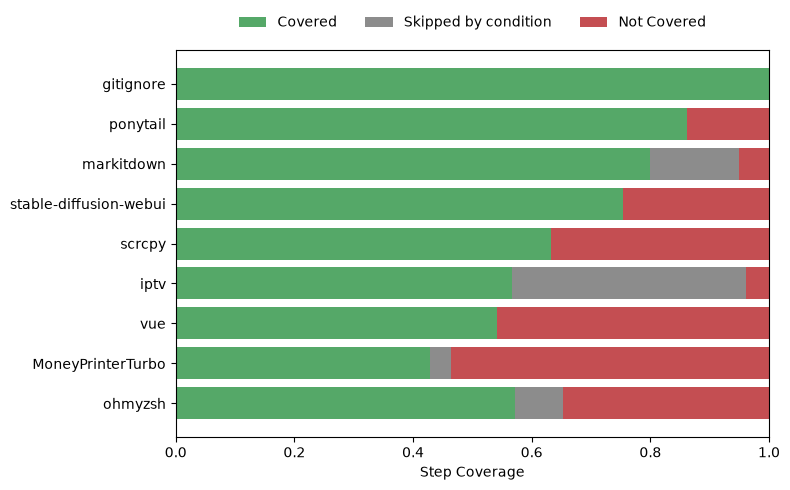

,executed,skipped_by_condition,not_reached,share executed
repo,,,,
gitignore,1,0,0,1.00
ponytail,62,0,10,0.86
markitdown,16,3,1,0.80
stable-diffusion-webui,46,0,15,0.75
scrcpy,19,0,11,0.63
iptv,59,41,4,0.57
vue,26,0,22,0.54
MoneyPrinterTurbo,24,2,30,0.43
ohmyzsh,28,4,17,0.57


281 of 441 steps executed; 110 not reached after a failure.


In [10]:
import matplotlib.pyplot as plt

by_repo = steps.groupby('repo').agg(executed=('ran', 'sum'), skipped_by_condition=('condition', 'sum'), not_reached=('not reached', 'sum')).reindex([repo for repo in REPOS if repo not in missing])
share = by_repo.div(by_repo.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(8, 5))
left = pd.Series(0.0, index=share.index)

for column, label, color in (('executed', 'Covered', '#55A868'), ('skipped_by_condition', 'Skipped by condition', '#8C8C8C'), ('not_reached', 'Not Covered', '#C44E52')):
    ax.barh(share.index, share[column], left=left, label=label, color=color)
    left += share[column]

ax.invert_yaxis()
ax.set_xlabel('Step Coverage')
ax.set_xlim(0, 1)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=False)
plt.tight_layout()
plt.savefig('step_coverage.pdf', bbox_inches='tight')
plt.show()

display(by_repo.assign(**{'share executed': share['executed'].round(2)}))
print(f'{by_repo["executed"].sum()} of {by_repo.sum().sum()} steps executed; {by_repo["not_reached"].sum()} not reached after a failure.')

In [12]:
jobs['bound'] = jobs['events'] * (1 + 2 * jobs['gates'])
per_repo_bound = jobs.groupby('repo').agg(variants=('tested', 'sum'), bound=('bound', 'sum'))
per_repo_bound['below bound'] = per_repo_bound['variants'] < per_repo_bound['bound']

print(f'{per_repo_bound["below bound"].sum()} of {len(per_repo_bound)} repositories have fewer variants than the upper bound; {(jobs["tested"] < jobs["bound"]).sum()} of {len(jobs)} jobs do.')
display(per_repo_bound.reindex([repo for repo in REPOS if repo not in missing]))

5 of 9 repositories have fewer variants than the upper bound; 19 of 50 jobs do.


,variants,bound,below bound
repo,,,
gitignore,1,1,False
ponytail,11,19,True
markitdown,4,4,False
stable-diffusion-webui,10,19,True
scrcpy,25,33,True
iptv,13,28,True
vue,9,9,False
MoneyPrinterTurbo,10,10,False
ohmyzsh,15,25,True
